# 06. Contexto

Teórica de series temporales, Analítica de Datos (UdeSA). Este cuaderno acompaña los bloques 5 y 6 de la clase.

Los modelos encuentran patrones; para explicarlos hace falta saber qué pasó. Las afirmaciones sobre hechos (aperturas, normas, precios) salen de `eventos_verificados.csv` o de la documentación de los datos, con la fuente citada en cada caso.

Contenido:

1. Lluvia: subte y Ecobici.
2. Puentes obligatorios y optativos.
3. El precio del boleto, en pesos corrientes y deflactado.
4. Ecobici: el cobro en fines de semana desde el 13/3/2021.
5. La red cambia: aperturas y cierres de estaciones.
6. Qué mide realmente cada dato.

In [1]:
import sys

# Dirección de los datos cuando el notebook corre en Colab.
# Si los datos se suben a otro lado, hay que cambiar esta constante.
URL_DATOS_COLAB = "https://raw.githubusercontent.com/ferkrodriguez98/teorica-series-temporales/main/datos_clase/"

EN_COLAB = "google.colab" in sys.modules
BASE = URL_DATOS_COLAB if EN_COLAB else "../datos_clase/"
print("Datos:", BASE)

Datos: ../datos_clase/


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Colores: tinta para lo observado, rojo para pronósticos y resaltados
TINTA, GRIS, ROJO = "#1f2430", "#9aa0a6", "#c62828"
LINEAS = {"A": "#1a9fd0", "B": "#d7182a", "C": "#1d4f9c", "D": "#008a57", "E": "#6c2c87", "H": "#e0a800"}
ECOBICI = "#d4a017"

warnings.simplefilter("ignore", FutureWarning)   # avisos de cambios en versiones futuras de las librerías

plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 100, "savefig.bbox": "tight",
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b0b0b0",
    "axes.titlesize": 11.5, "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": "#444444", "xtick.color": "#555555", "ytick.color": "#555555",
    "legend.frameon": False, "legend.fontsize": 9.5, "lines.linewidth": 1.1,
})

def num(x, dec=0):
    # Número con punto de miles y coma decimal
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(x, dec=0):
    return num(100 * x, dec) + " %"

en_millones = FuncFormatter(lambda v, _: num(v / 1e6, 1))
en_miles = FuncFormatter(lambda v, _: num(v / 1e3))

DIAS3 = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

def cociente(serie):
    # Cada día dividido la mediana del mismo día de la semana en las 4 semanas anteriores y las 4 siguientes
    vecinos = pd.concat([serie.shift(k) for k in (-28, -21, -14, -7, 7, 14, 21, 28)], axis=1)
    return (serie / vecinos.median(axis=1)).where(vecinos.notna().sum(axis=1) >= 5)

In [3]:
total = pd.read_csv(BASE + "subte_diario_total.csv", parse_dates=["fecha"], index_col="fecha")["pax"].asfreq("D")
linea = pd.read_csv(BASE + "subte_diario_linea.csv", parse_dates=["fecha"]).pivot(index="fecha", columns="linea", values="pax")
estacion = pd.read_csv(BASE + "subte_diario_estacion.csv.gz", parse_dates=["fecha"])
ecobici = pd.read_csv(BASE + "ecobici_diario.csv", parse_dates=["fecha"], index_col="fecha")["viajes"].asfreq("D")
clima = pd.read_csv(BASE + "clima_diario.csv", parse_dates=["fecha"], index_col="fecha")
fer = pd.read_csv(BASE + "feriados.csv", parse_dates=["fecha"])
fer = fer[(fer["ambito"] == "nacional") | fer["ambito"].str.startswith("CABA")]
no_habiles = set(fer["fecha"])
eventos = pd.read_csv(BASE + "eventos_verificados.csv", parse_dates=["fecha"])
pd.set_option("display.max_colwidth", 120)
print("Subte:", total.index.min().date(), "a", total.index.max().date(), "| Ecobici:", ecobici.index.min().date(), "a", ecobici.index.max().date())

Subte: 2013-06-01 a 2026-08-31 | Ecobici: 2014-01-02 a 2026-09-30


## 1. Lluvia: subte y Ecobici

Para cada día hábil no feriado desde abril de 2022: el cociente entre el día y la mediana del mismo día de la semana en las semanas vecinas (el método del cuaderno 01), agrupado según la lluvia del día. La lluvia es la suma diaria de Open-Meteo (reanálisis) para la Ciudad.

mediana          días        
                Subte Ecobici Subte Ecobici
lluvia                                     
menos de 1 mm    1.01    1.04   824     845
1 a 5 mm         1.01    0.97   113     115
5 a 15 mm        0.99    0.87    75      75
15 a 30 mm       0.95    0.57    40      41
30 mm o más      0.94    0.56    18      18

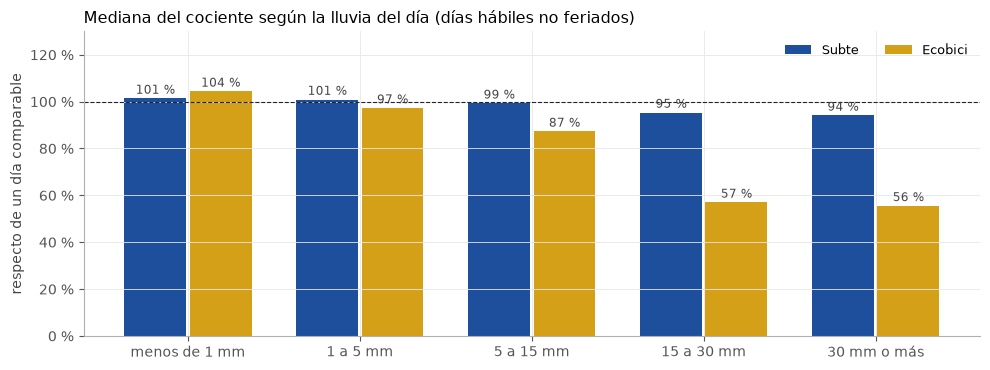

In [4]:
d = pd.DataFrame({"Subte": cociente(total), "Ecobici": cociente(ecobici)}).join(clima["precipitacion_mm"])
d = d.loc["2022-04-01":]
d = d[(d.index.day_of_week < 5) & ~d.index.isin(no_habiles)]
categorias = ["menos de 1 mm", "1 a 5 mm", "5 a 15 mm", "15 a 30 mm", "30 mm o más"]
d["lluvia"] = pd.cut(d["precipitacion_mm"], [0, 1, 5, 15, 30, np.inf], right=False, labels=categorias)

res = d.groupby("lluvia", observed=False)[["Subte", "Ecobici"]].median()
n = d.groupby("lluvia", observed=False)[["Subte", "Ecobici"]].count()

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(categorias))
for k, (serie, color) in enumerate((("Subte", LINEAS["C"]), ("Ecobici", ECOBICI))):
    barras = ax.bar(x + (k - 0.5) * 0.38, res[serie], width=0.36, color=color, label=serie)
    for b, v in zip(barras, res[serie]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, pct(v), ha="center", fontsize=8.5, color="#444444")
ax.axhline(1, color=TINTA, ls="--", lw=0.8)
ax.set_xticks(x, categorias)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v)))
ax.set_ylim(0, 1.3)
ax.set_ylabel("respecto de un día comparable")
ax.set_title("Mediana del cociente según la lluvia del día (días hábiles no feriados)")
ax.legend(loc="upper right", ncol=2)
fig.tight_layout()
pd.concat({"mediana": res.round(2), "días": n}, axis=1)

La lluvia casi no mueve al subte y reduce mucho los viajes de Ecobici. En un modelo de Ecobici conviene incluirla; en uno del subte su efecto es chico. Con más de 30 mm hay pocos días, así que esa mediana es menos estable.

## 2. Puentes obligatorios y optativos

Los días no laborables con fines turísticos (los puentes) no tienen el mismo carácter legal todos los años. En `feriados.csv`, la columna `caracter_legal` dice si la norma los definió como **feriado** (descanso obligatorio, con los mismos derechos que un feriado nacional según el art. 4 del [Decreto 1584/2010](https://www.argentina.gob.ar/normativa/nacional/norma-174389/texto)) o como **día no laborable** (cada empleador privado decide si se trabaja; [Ley 27.399](https://www.argentina.gob.ar/normativa/nacional/norma-281835/texto)).

,mediana,puentes
caracter_legal,,
feriado,28 %,20
no laborable,38 %,11


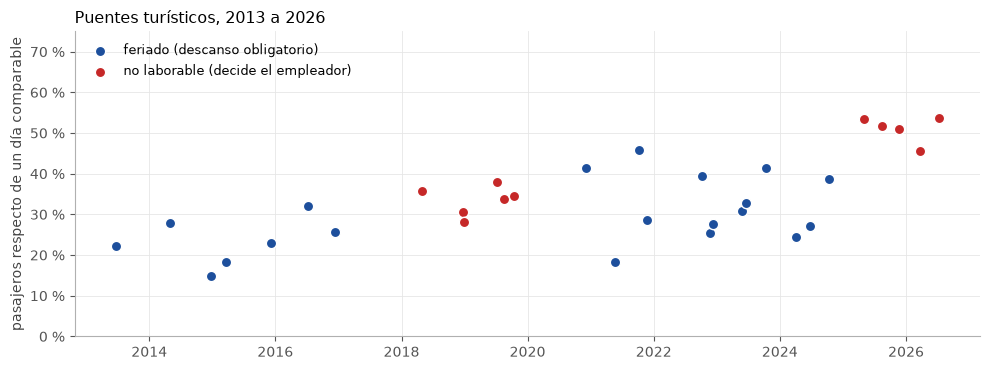

In [5]:
r_total = cociente(total)
puentes = fer[fer["tipo"] == "día no laborable con fines turísticos"][["fecha", "caracter_legal", "fuente"]].copy()
puentes["cociente"] = puentes["fecha"].map(r_total)
puentes = puentes.dropna(subset=["cociente"])
puentes = puentes[~puentes["fecha"].between("2020-03-01", "2020-11-30")]   # sin los puentes de la cuarentena

fig, ax = plt.subplots(figsize=(10, 3.8))
for caracter, color, nombre in (("feriado", LINEAS["C"], "feriado (descanso obligatorio)"), ("no laborable", ROJO, "no laborable (decide el empleador)")):
    p = puentes[puentes["caracter_legal"] == caracter]
    ax.scatter(p["fecha"], p["cociente"], s=55, color=color, edgecolor="white", label=nombre, zorder=3)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v)))
ax.set_ylim(0, 0.75)
ax.set_ylabel("pasajeros respecto de un día comparable")
ax.set_title("Puentes turísticos, 2013 a 2026")
ax.legend(loc="upper left")
fig.tight_layout()

resumen = puentes.groupby("caracter_legal")["cociente"].agg(["median", "count"]).rename(columns={"median": "mediana", "count": "puentes"})
resumen["mediana"] = resumen["mediana"].map(pct)
resumen

In [6]:
puentes.assign(año=puentes["fecha"].dt.year).groupby(["año", "caracter_legal"])["fuente"].first().to_frame()

,,fuente
año,caracter_legal,
2013,feriado,Decreto 1584/2010 art. 3 y Decreto 1585/2010
2014,feriado,Decreto 1584/2010 art. 3 y Decreto 1768/2013
2015,feriado,Decreto 1584/2010 art. 3 y Decreto 1768/2013
2016,feriado,Decreto 1584/2010 art. 3 y Decreto 1768/2013
2018,no laborable,Ley 27.399 art. 7; Decreto 923/2017
2019,no laborable,Ley 27.399 art. 7; Decreto 923/2017
2020,feriado,Ley 27.399 art. 7; Decreto 717/2019
2021,feriado,Ley 27.399 art. 7; Decreto 947/2020
2022,feriado,Ley 27.399 art. 7; Decreto 789/2021


Cuando el puente es día no laborable viaja bastante más gente que cuando es feriado. En un modelo conviene distinguir los dos casos con la columna `caracter_legal`.

## 3. El precio del boleto

`precio_boleto_mensual.csv` tiene la tarifa del subte del primer escalón (viajes 1 a 20 del mes), con SUBE registrada desde octubre de 2024, promediada según los días de vigencia de cada precio en el mes. Es la tarifa nominal: no descuenta los escalones, la tarifa social ni las promociones, así que no es el precio medio que pagan los usuarios. Para comparar precios de distintos años se deflacta con el índice de precios al consumidor (IPC): el precio de cada mes se lleva a pesos del último mes con índice publicado.

$$\text{precio en pesos de } m^* = \text{precio}_m \times \frac{\text{IPC}_{m^*}}{\text{IPC}_m}$$

In [7]:
boleto = pd.read_csv(BASE + "precio_boleto_mensual.csv")
ipc = pd.read_csv(BASE + "ipc_mensual.csv").dropna(subset=["indice"])
base = ipc.iloc[-1]
nombre_base = f"{MESES[int(base['mes'][5:]) - 1]} de {base['mes'][:4]}"
b = boleto.merge(ipc[["mes", "indice"]], on="mes", how="inner")
b["nominal"] = b["precio_promedio_ponderado_dias"]
b["real"] = b["nominal"] * base["indice"] / b["indice"]
b["fecha"] = pd.to_datetime(b["mes"] + "-15")
pax_mes = total.resample("MS").mean()
b["pax_dia"] = b["fecha"].dt.to_period("M").map(lambda m: pax_mes.get(m.to_timestamp()))
print("Precios llevados a pesos de", nombre_base)
b.set_index("mes").loc[["2013-06", "2019-12", "2023-12", "2024-06", base["mes"]], ["nominal", "real", "pax_dia"]].round(1)

Precios llevados a pesos de octubre de 2026


,nominal,real,pax_dia
mes,,,
2013-06,2.5,902.8,762955.8
2019-12,19.0,857.1,895349.4
2023-12,80.0,289.5,664107.9
2024-06,650.0,1308.4,461572.1
2026-10,1817.0,1817.0,NaN


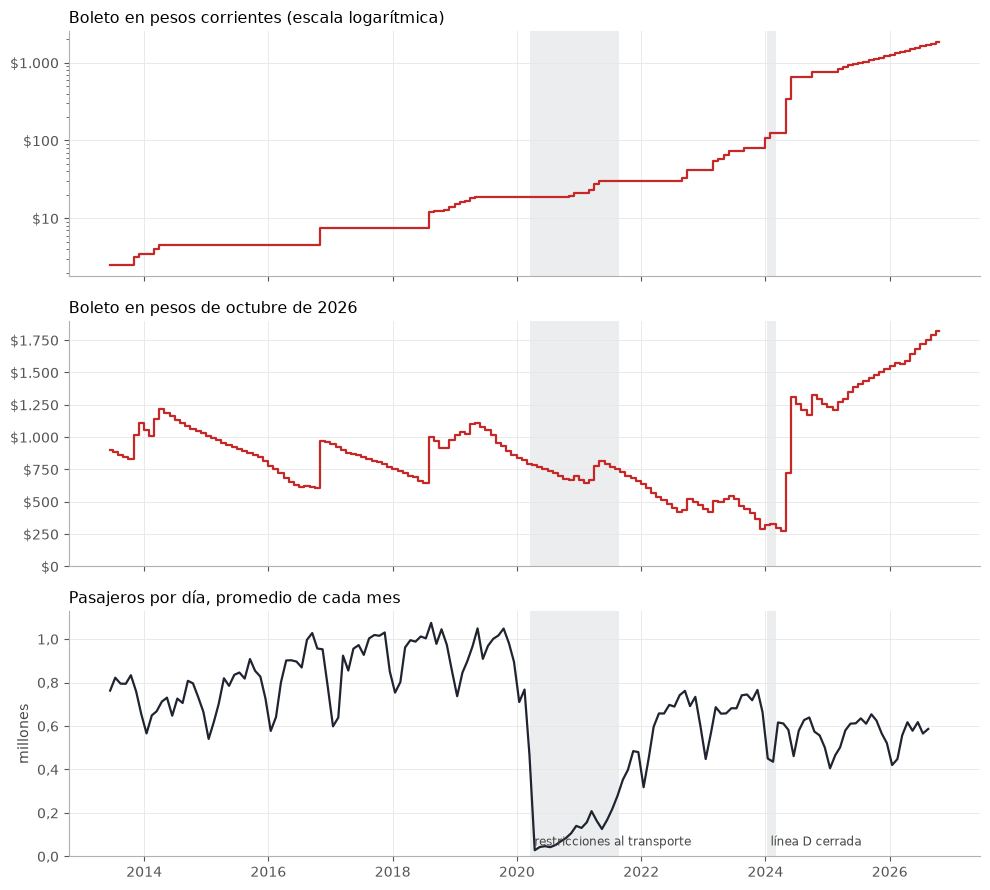

In [8]:
marcas = [("2020-03-20", "2021-08-24", "restricciones al transporte"), ("2024-01-08", "2024-03-06", "línea D cerrada")]
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
axes[0].step(b["fecha"], b["nominal"], where="mid", color=ROJO, lw=1.6)
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: "$" + num(v, 2 if v < 10 else 0)))
axes[0].set_title("Boleto en pesos corrientes (escala logarítmica)")
axes[1].step(b["fecha"], b["real"], where="mid", color=ROJO, lw=1.6)
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: "$" + num(v)))
axes[1].set_ylim(bottom=0)
axes[1].set_title(f"Boleto en pesos de {nombre_base}")
axes[2].plot(b["fecha"], b["pax_dia"], color=TINTA, lw=1.6)
axes[2].yaxis.set_major_formatter(en_millones)
axes[2].set_ylim(bottom=0)
axes[2].set_ylabel("millones")
axes[2].set_title("Pasajeros por día, promedio de cada mes")
for ax in axes:
    for desde, hasta, texto in marcas:
        ax.axvspan(pd.Timestamp(desde), pd.Timestamp(hasta), color=GRIS, alpha=0.18, lw=0)
for desde, hasta, texto in marcas:
    axes[2].text(pd.Timestamp(desde), 0.05e6, " " + texto, fontsize=8.5, color="#444444")
fig.tight_layout()

Las bandas grises son el período en que el transporte público estuvo reservado a actividades esenciales, del 20/3/2020 ([DNU 297/2020](https://www.boletinoficial.gob.ar/detalleAviso/primera/227042/20200320)) al 24/8/2021 ([Infobae, 24/8/2021](https://www.infobae.com/sociedad/2021/08/24/el-transporte-publico-en-el-amba-dejo-de-ser-solo-para-esenciales/)), y el cierre de la línea D de 2024.

En pesos corrientes el boleto sube siempre, como cualquier precio en un período de inflación alta. Deflactado, se ven las etapas: el boleto pierde valor real durante años y en 2024 vuelve a subir de golpe. Según La Nación, pasó de \$125 a \$574 el 17/5/2024 y a \$650 el 1/6/2024 ([La Nación, 17/5/2024](https://www.lanacion.com.ar/buenos-aires/cual-es-el-precio-del-subte-a-partir-de-hoy-y-cuanto-aumentara-en-los-proximos-meses-nid17052024/)); Ámbito informó en agosto de 2024 que, tras los aumentos, "se redujo en un 24% la cantidad de pasajeros" ([Ámbito, 10/8/2024](https://www.ambito.com/economia/subte-los-aumentos-cayo-un-24-la-cantidad-pasajeros-y-la-brecha-el-colectivo-es-record-n6046232)).

En los mismos meses la línea D estuvo cerrada del 8/1 al 6/3/2024 por obras de señalización ([GCBA, 7/1/2024](https://buenosaires.gob.ar/noticias/este-lunes-comenzo-una-nueva-etapa-de-obras-en-la-linea-d-de-subte); [La Nación, 6/3/2024](https://lanacion.com.ar/sociedad/subte-cuando-volvera-a-abrir-la-linea-d-nid06032024)). Con dos cambios a la vez, la serie sola no permite separar cuánto de la caída de 2024 se debe a cada uno.

## 4. Ecobici: el cobro en fines de semana

Desde el sábado 13/3/2021, Ecobici es gratis para los residentes solo de lunes a viernes hábiles; los fines de semana y feriados pasaron a pagar ([Infobae, 12/3/2021](https://www.infobae.com/sociedad/2021/03/12/desde-manana-habra-que-pagar-por-usar-el-sistema-de-ecobici-en-la-ciudad-de-buenos-aires/); [Ámbito, 14/3/2021](https://www.ambito.com/viajes/el-sistema-ecobici-porteno-dejo-ser-gratis-cuales-son-los-precios-usar-las-bicicletas-n5176631)).

Para cada semana (lunes a domingo, sin feriados): viajes promedio de sábado y domingo dividido el promedio de lunes a viernes.

Mediana de junio de 2020 al 12/3/2021: 94 % | desde el 13/3/2021: 38 %


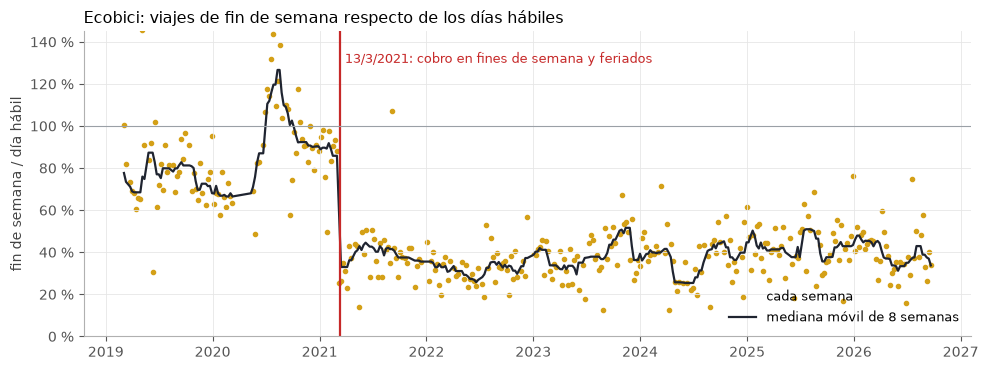

In [9]:
e = ecobici.loc["2019-03-04":].dropna().to_frame("viajes")
e = e[~e.index.isin(no_habiles)]
e["semana"] = e.index - pd.to_timedelta(e.index.day_of_week, unit="D")
e["finde"] = e.index.day_of_week >= 5
g = e.groupby(["semana", "finde"])["viajes"].agg(["mean", "count"]).unstack()
g = g[(g[("count", False)] >= 3) & (g[("count", True)] == 2)]
semanal = (g[("mean", True)] / g[("mean", False)]).rename("fin de semana / hábil")

COBRO = pd.Timestamp("2021-03-13")
antes = semanal.loc["2020-06-01":COBRO - pd.Timedelta(days=1)].median()
despues = semanal.loc[COBRO:].median()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(semanal.index, semanal.values, s=9, color=ECOBICI, label="cada semana")
ax.plot(semanal.index, semanal.rolling(8, center=True, min_periods=4).median(), color=TINTA, lw=1.6, label="mediana móvil de 8 semanas")
ax.axvline(COBRO, color=ROJO, lw=1.6)
ax.text(COBRO + pd.Timedelta(days=15), 1.3, "13/3/2021: cobro en fines de semana y feriados", color=ROJO, fontsize=9)
ax.axhline(1, color=GRIS, lw=0.8)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v)))
ax.set_ylim(0, 1.45)
ax.set_ylabel("fin de semana / día hábil")
ax.set_title("Ecobici: viajes de fin de semana respecto de los días hábiles")
ax.legend(loc="lower right")
fig.tight_layout()
print("Mediana de junio de 2020 al 12/3/2021:", pct(antes), "| desde el 13/3/2021:", pct(despues))

El cobro coincide al día con el derrumbe de los fines de semana; los días hábiles, que siguieron gratis para los residentes, no cambian. Un cambio de precio para un subconjunto de días cambia la forma del ciclo semanal, no solo el nivel. Un modelo entrenado antes de esa fecha pronosticaría mal todos los fines de semana posteriores.

## 5. La red cambia

### Aperturas de estaciones

Fecha de inauguración según la prensa y el Gobierno de la Ciudad (hechos verificados en la documentación de los datos), contra el primer día con al menos 100 pasajeros en los datos de molinetes.

In [10]:
aperturas = pd.DataFrame([
    ("A", "SAN PEDRITO", "2013-09-27", "https://buenosaires.gob.ar/gcaba_historico/noticias/la-extension-de-la-red-de-subterraneos"),
    ("A", "FLORES", "2013-09-27", "https://buenosaires.gob.ar/gcaba_historico/noticias/la-extension-de-la-red-de-subterraneos"),
    ("B", "ECHEVERRIA", "2013-07-26", "https://www.pagina12.com.ar/imprimir/diario/ultimas/20-225535-2013-07-29.html"),
    ("B", "ROSAS", "2013-07-26", "https://www.pagina12.com.ar/imprimir/diario/ultimas/20-225535-2013-07-29.html"),
    ("H", "LAS HERAS", "2015-12-18", "https://www.infobae.com/2015/12/18/1777356-mauricio-macri-inauguro-dos-estaciones-subte/"),
    ("H", "CORDOBA", "2015-12-18", "https://www.infobae.com/2015/12/18/1777356-mauricio-macri-inauguro-dos-estaciones-subte/"),
    ("H", "SANTA FE", "2016-07-12", "https://www.infobae.com/sociedad/2016/07/12/inauguran-la-estacion-santa-fe-de-la-linea-h/"),
    ("H", "FACULTAD DE DERECHO", "2018-05-17", "https://www.casarosada.gob.ar/informacion/discursos/42732-el-presidente-mauricio-macri-en-la-inauguracion-de-una-nueva-estacion-de-la-linea-h-de-subte-en-la-ciudad-de-buenos-aires"),
    ("E", "CORREO CENTRAL", "2019-06-03", "https://www.lanacion.com.ar/buenos-aires/subte-inauguraron-tres-estaciones-linea-e-llega-nid2254076"),
    ("E", "CATALINAS", "2019-06-03", "https://www.lanacion.com.ar/buenos-aires/subte-inauguraron-tres-estaciones-linea-e-llega-nid2254076"),
    ("E", "RETIRO E", "2019-06-03", "https://www.lanacion.com.ar/buenos-aires/subte-inauguraron-tres-estaciones-linea-e-llega-nid2254076"),
], columns=["linea", "estacion", "inauguracion", "fuente"])
aperturas["inauguracion"] = pd.to_datetime(aperturas["inauguracion"])

def primer_dia(fila, minimo):
    s = estacion[(estacion["linea"] == fila.linea) & (estacion["estacion"] == fila.estacion) & (estacion["pax"] >= minimo)]
    return s["fecha"].min()

aperturas["primer registro"] = [primer_dia(f, 0) for f in aperturas.itertuples()]
aperturas["primer día con 100 o más"] = [primer_dia(f, 100) for f in aperturas.itertuples()]
aperturas["diferencia (días)"] = (aperturas["primer día con 100 o más"] - aperturas["inauguracion"]).dt.days
aperturas.drop(columns="fuente")

,linea,estacion,inauguracion,primer registro,primer día con 100 o más,diferencia (días)
0,A,SAN PEDRITO,2013-09-27,2013-09-06,2013-09-27,0
1,A,FLORES,2013-09-27,2013-09-10,2013-09-27,0
2,B,ECHEVERRIA,2013-07-26,2013-07-25,2013-07-26,0
3,B,ROSAS,2013-07-26,2013-07-25,2013-07-26,0
4,H,LAS HERAS,2015-12-18,2015-12-10,2015-12-18,0
5,H,CORDOBA,2015-12-18,2015-12-16,2015-12-18,0
6,H,SANTA FE,2016-07-12,2016-07-05,2016-07-12,0
7,H,FACULTAD DE DERECHO,2018-05-17,2018-05-11,2018-05-17,0
8,E,CORREO CENTRAL,2019-06-03,2019-06-02,2019-06-03,0
9,E,CATALINAS,2019-06-03,2019-06-03,2019-06-03,0


Fuentes de las fechas de inauguración: línea A, [GCBA, 28/9/2013](https://buenosaires.gob.ar/gcaba_historico/noticias/la-extension-de-la-red-de-subterraneos); línea B, [Página/12, 29/7/2013](https://www.pagina12.com.ar/imprimir/diario/ultimas/20-225535-2013-07-29.html); Córdoba y Las Heras, [Infobae, 18/12/2015](https://www.infobae.com/2015/12/18/1777356-mauricio-macri-inauguro-dos-estaciones-subte/); Santa Fe, [Infobae, 12/7/2016](https://www.infobae.com/sociedad/2016/07/12/inauguran-la-estacion-santa-fe-de-la-linea-h/); Facultad de Derecho, [La Nación, 17/5/2018](https://www.lanacion.com.ar/sociedad/side-drift-el-innovador-sistema-con-el-que-se-construyo-la-nueva-estacion-del-subte-h-nid2135589/); línea E, [La Nación, 3/6/2019](https://www.lanacion.com.ar/buenos-aires/subte-inauguraron-tres-estaciones-linea-e-llega-nid2254076).

La primera fecha con registros no es la inauguración: antes aparecen días con 0 a 2 pasajeros, compatibles con pruebas, que ninguna fuente menciona. El primer día con pasajeros coincide con la inauguración. Echeverría y Juan Manuel de Rosas (B) tienen además un hueco del 1 al 14/8/2013: los trenes dejaron de llegar a esas dos estaciones por un conflicto gremial ([La Nación, 1/8/2013](https://www.lanacion.com.ar/buenos-aires/la-linea-b-de-subte-llega-solo-hasta-los-incas-nid1606375); [Página/12, 14/8/2013](https://www.pagina12.com.ar/diario/sociedad/3-226718-2013-08-14.html)).

Cada estación nueva suma pasajeros a su línea:

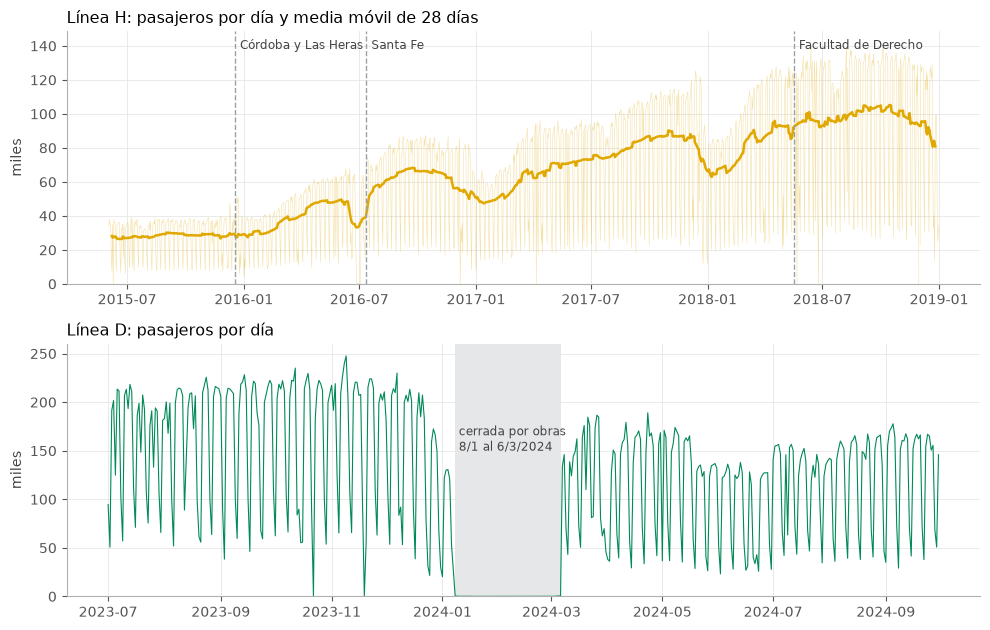

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.4))
h = linea["H"].loc["2015-06":"2018-12"]
axes[0].plot(h.index, h.rolling(28, center=True, min_periods=20).mean(), color=LINEAS["H"], lw=1.8)
axes[0].plot(h.index, h.values, color=LINEAS["H"], lw=0.4, alpha=0.35)
for f in ("2015-12-18", "2016-07-12", "2018-05-17"):
    axes[0].axvline(pd.Timestamp(f), color=GRIS, ls="--", lw=1)
for f, texto in (("2015-12-18", "Córdoba y Las Heras"), ("2016-07-12", "Santa Fe"), ("2018-05-17", "Facultad de Derecho")):
    axes[0].text(pd.Timestamp(f) + pd.Timedelta(days=8), 0.93, texto, fontsize=8.5, color="#444444", transform=axes[0].get_xaxis_transform())
axes[0].set_title("Línea H: pasajeros por día y media móvil de 28 días")

dd = linea["D"].loc["2023-07":"2024-09"]
axes[1].plot(dd.index, dd.values, color=LINEAS["D"], lw=0.8)
axes[1].axvspan(pd.Timestamp("2024-01-08"), pd.Timestamp("2024-03-06"), color=GRIS, alpha=0.25, lw=0)
axes[1].text(pd.Timestamp("2024-01-10"), 1.5e5, "cerrada por obras\n8/1 al 6/3/2024", fontsize=8.5, color="#444444")
axes[1].set_title("Línea D: pasajeros por día")
for ax in axes:
    ax.yaxis.set_major_formatter(en_miles)
    ax.set_ylabel("miles")
    ax.set_ylim(bottom=0)
fig.tight_layout()

### Cierres de estaciones

Entre 2024 y 2026 varias estaciones cerraron por obras. Facultad de Medicina (D) siguió cerrada después de la reapertura de la línea y volvió el 1/4/2024 ([Infobae, 1/4/2024](https://www.infobae.com/sociedad/2024/04/01/subtes-reabrio-la-estacion-facultad-de-medicina-luego-de-su-remodelacion/)). Las demás cerraron por el Plan de Renovación Integral de SBASE:

| Estación | Cierre | Reapertura | Fuentes |
|---|---|---|---|
| Scalabrini Ortiz (D) | 21/10/2024 | 24/2/2025 | [GCBA, 18/10/2024](https://buenosaires.gob.ar/gcaba_historico/noticias/subte-el-lunes-21-cerrara-la-estacion-scalabrini-ortiz-por-obras-de); [GCBA, 21/2/2025](https://buenosaires.gob.ar/gcaba_historico/noticias/reabre-la-estacion-scalabrini-ortiz-tras-su-renovacion-integral) |
| Palermo (D) | 9/12/2024 | 25/3/2025 | [Infobae, 9/12/2024](https://www.infobae.com/sociedad/2024/12/09/cierra-otra-estacion-de-subte-de-la-linea-d-por-reformas-integrales/); [GCBA, 26/3/2025](https://buenosaires.gob.ar/noticias/la-estacion-palermo-de-la-linea-d-reabrio-tras-su-renovacion-integral) |
| Tribunales (D) | 2/3/2026 | 5/10/2026 (fuera de los datos) | [La Nación, 27/2/2026](https://www.lanacion.com.ar/sociedad/confirmado-este-lunes-cierra-una-estacion-de-subte-de-la-linea-d-por-reformas-nid27022026/); [GCBA, 2/10/2026](https://buenosaires.gob.ar/gcaba_historico/noticias/el-lunes-reabre-la-estacion-tribunales-tras-las-obras-de-renovacion-0) |
| General Urquiza (E) | 3/8/2026 | | [GCBA, 31/7/2026](https://buenosaires.gob.ar/gcaba_historico/noticias/el-lunes-3-de-agosto-cierra-la-estacion-general-urquiza-por-obras-de) |
| Entre Ríos (E) | 20/8/2026 | | [GCBA, 19/8/2026](https://buenosaires.gob.ar/gcaba_historico/noticias/subte-manana-cierra-la-estacion-entre-rios-por-obras-de-renovacion) |

En los datos, cada cierre es un tramo sin pasajeros en esa estación:

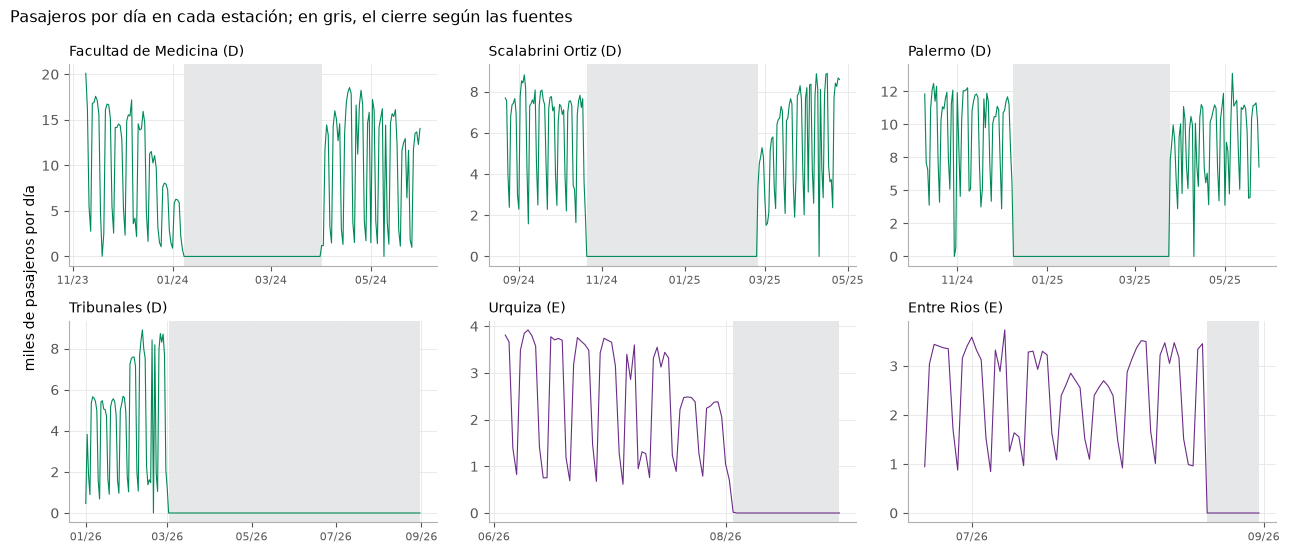

In [12]:
cierres = [
    ("D", "FACULTAD DE MEDICINA", "2024-01-08", "2024-04-01"),
    ("D", "SCALABRINI ORTIZ", "2024-10-21", "2025-02-24"),
    ("D", "PALERMO", "2024-12-09", "2025-03-25"),
    ("D", "TRIBUNALES", "2026-03-02", None),
    ("E", "URQUIZA", "2026-08-03", None),
    ("E", "ENTRE RIOS", "2026-08-20", None),
]
fin_datos = total.index.max()
fig, axes = plt.subplots(2, 3, figsize=(13, 5.6))
for ax, (lin, nombre, desde, hasta) in zip(axes.flat, cierres):
    desde = pd.Timestamp(desde)
    hasta = pd.Timestamp(hasta) if hasta else fin_datos
    s = estacion[(estacion["linea"] == lin) & (estacion["estacion"] == nombre)].set_index("fecha")["pax"]
    s = s.reindex(pd.date_range(desde - pd.Timedelta(days=60), min(hasta + pd.Timedelta(days=60), fin_datos)), fill_value=0)
    ax.axvspan(desde, min(hasta, fin_datos), color=GRIS, alpha=0.25, lw=0)
    ax.plot(s.index, s.values, color=LINEAS[lin], lw=0.8)
    ax.set_title(f"{nombre.title().replace(' De ', ' de ')} ({lin})", fontsize=10)
    ax.yaxis.set_major_formatter(en_miles)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
    ax.tick_params(axis="x", labelsize=8)
fig.supylabel("miles de pasajeros por día", fontsize=10)
fig.suptitle("Pasajeros por día en cada estación; en gris, el cierre según las fuentes", x=0.01, ha="left", fontsize=11.5)
fig.tight_layout()

## 6. Qué mide realmente cada dato

**Molinetes del subte.** Cuentan pasadas registradas al entrar, pagas o con franquicia. No cuentan salidas (a la mañana se ve dónde sube la gente, no adónde va) ni a quien viaja gratis: cuando el subte fue gratuito, la serie casi desaparece aunque el servicio funcionó.

In [13]:
gratis = eventos[eventos["descripcion"].str.contains("gratu|gratis", case=False) & eventos["descripcion"].str.contains("molinete")]
gratis[["fecha", "ratio", "tipo", "descripcion", "fuente_url"]]

,fecha,ratio,tipo,descripcion,fuente_url
6,2013-12-01,0.008,otro,"Centenario del subte: el Gobierno porteño habilitó viajar gratis todo el día en toda la red, por eso los molinetes c...",https://www.ambito.com/informacion-general/se-cumplieron-100-anos-del-primer-viaje-subte-n3818445
188,2021-11-14,NaN,elecciones,"Elecciones legislativas: subte y Premetro gratuitos desde las 7, por eso no hay registros de molinetes.",https://www.infobae.com/politica/2021/11/14/transporte-publico-gratis-para-votar-los-detalles-que-tenes-que-saber/
236,2023-08-13,NaN,elecciones,"Elecciones PASO: subte, Premetro y Ecobici gratuitos, por eso no hay registros de molinetes.",https://www.infobae.com/sociedad/2023/08/09/como-funcionara-el-transporte-publico-durante-las-paso-2023-en-caba/
240,2023-10-22,0.001,elecciones,"Elecciones generales: subte gratuito desde las 7, por eso los molinetes casi no registran pasadas.",https://www.cronista.com/economia-politica/elecciones-2023-son-gratis-los-colectivos-tren-y-subte-hoy-22-de-octubre-...
241,2023-11-19,0.003,elecciones,"Segunda vuelta presidencial: subte, Premetro y Ecobici gratuitos, por eso los molinetes casi no registran pasadas.",https://buenosaires.gob.ar/gcaba_historico/noticias/buenos-aires-habilitara-el-uso-gratuito-del-subte-y-de-ecobici-p...


**Medios de pago.** Desde el lunes 2/12/2024 se puede pagar con tarjetas sin contacto y con el celular ([La Nación, 2/12/2024](https://www.lanacion.com.ar/sociedad/pago-del-subte-con-tarjetas-o-celular-las-14-claves-para-utilizar-el-sistema-en-la-ciudad-de-buenos-nid02122024/)). Ese mismo día aparecen en los datos estaciones de combinación con un sufijo de línea (`RETIRO.C`, `PUEYRREDON.B`; `CALLAO.B`, `PUEYRREDON.D` e `INDEPENDENCIA.H` ya existían desde 2015). El dataset no documenta qué significan; para armar una serie por estación hay que sumar los dos nombres.

In [14]:
sufijo = estacion[estacion["estacion"].str.contains(r"\.[A-Z]$", regex=True)]
sufijo.groupby(["linea", "estacion"])["fecha"].agg(["min", "max"]).rename(columns={"min": "primer día", "max": "último día"})

primer día último día
linea estacion                             
B     CALLAO.B        2015-01-02 2026-08-31
      PUEYRREDON.B    2024-12-02 2026-08-31
C     INDEPENDENCIA.C 2024-12-02 2026-08-31
      RETIRO.C        2024-12-02 2026-08-31
D     CALLAO.D        2024-12-12 2026-08-31
      PUEYRREDON.D    2015-01-01 2026-08-31
E     INDEPENDENCIA.E 2024-12-02 2026-08-31
      INDEPENDENCIA.H 2015-01-01 2026-06-30
      RETIRO.E        2024-12-02 2026-08-31

El total de la red no salta con el cambio. Media de los días hábiles no feriados del 1 al 20 de diciembre dividida la del 11 al 30 de noviembre, para cada año:

In [15]:
filas = {}
for anio in range(2016, 2025):
    if anio in (2020, 2021):
        continue
    s = total.loc[f"{anio}-11-11":f"{anio}-12-20"].dropna()
    s = s[(s.index.day_of_week < 5) & ~s.index.isin(no_habiles)]
    nov, dic = s.loc[f"{anio}-11"].mean(), s.loc[f"{anio}-12"].mean()
    filas[anio] = {"noviembre": round(nov), "diciembre": round(dic), "dic / nov": round(dic / nov, 2)}
pd.DataFrame(filas).T

,noviembre,diciembre,dic / nov
2016,1217427.0,1069372.0,0.88
2017,1296665.0,1221679.0,0.94
2018,1270111.0,1287220.0,1.01
2019,1261653.0,1288010.0,1.02
2022,880041.0,868695.0,0.99
2023,946109.0,917104.0,0.97
2024,701685.0,706709.0,1.01


**El Premetro** aparece en los datos recién en junio de 2025, y solo en algunos meses. Funcionaba desde antes (el Gobierno de la Ciudad informó en febrero de 2024 la renovación de sus paradores, [GCBA, 7/2/2024](https://buenosaires.gob.ar/noticias/comenzo-la-obra-de-renovacion-de-estaciones-del-premetro)): es un cambio en lo que se publica, no el comienzo del servicio.

In [16]:
pm = estacion[estacion["linea"] == "PM"]
pm.groupby([pm["fecha"].dt.to_period("M"), "estacion"])["pax"].sum().unstack(fill_value=0)

estacion,COCHEPM,SAGUIER
fecha,,
2025-06,18324,55051
2025-07,25556,58404
2026-01,107179,19035
2026-02,118537,16054
2026-04,179706,24593
2026-06,179578,24305
2026-07,172844,22548


**Días sin datos.** Algunos días no tienen ningún registro. Hay paros sin servicio y también elecciones con subte gratuito: hubo servicio, pero los molinetes no contaron a nadie.

In [17]:
faltan = total[total.isna()].index
eventos.set_index("fecha").reindex(faltan)[["tipo", "descripcion"]].fillna("(sin fila en eventos_verificados)")

,tipo,descripcion
fecha,,
2014-01-01,datos_incompletos,Año Nuevo (feriado nacional); la fecha no tiene registros en el archivo de molinetes.
2019-04-30,paro_subte,Paro del 30 de abril de 2019 (no convocado por la CGT): los metrodelegados adhirieron y el subte no funcionó en todo...
2019-05-01,paro_general,"Feriado del Día del Trabajador con paro de transporte de la CATT: no funcionaron colectivos, trenes ni subtes."
2019-05-29,paro_general,"Paro general de la CGT y las CTA: desde las 0 h no circularon colectivos, trenes ni subtes."
2021-11-14,elecciones,"Elecciones legislativas: subte y Premetro gratuitos desde las 7, por eso no hay registros de molinetes."
2023-08-13,elecciones,"Elecciones PASO: subte, Premetro y Ecobici gratuitos, por eso no hay registros de molinetes."
2024-05-09,paro_general,Paro general de la CGT: los metrodelegados adhirieron las 24 h y no hubo servicio en ninguna línea ni en el Premetro.
2024-10-30,paro_general,Paro nacional de transporte de 24 h (CATT y UGATT): los metrodelegados adhirieron y no funcionaron el subte ni el Pr...


**Ecobici.** Cada viaje cuenta en la fecha y hora en que se retira la bicicleta. Hubo tres sistemas con identificadores de estación distintos (manual en 2014, automático de 2015 a 2018, el actual desde 2019), y la cantidad de estaciones cambió mucho. Según la documentación de los datos, el archivo de 2024 incluye viajes de menos de 60 segundos (el 9,1 % del año) que los otros años del sistema actual no traen.

In [18]:
est_eco = pd.read_csv(BASE + "ecobici_estaciones.csv")
print(est_eco.groupby("sistema")["sistema_desc"].first().to_string())
anual = ecobici.groupby(ecobici.index.year).agg(dias_con_viajes="count", mediana_diaria="median")
anual = anual.round(0).astype(int)
anual.T

sistema
A        A: 2015 a 2018, estaciones automáticas, ids numéricos
B    B: 2019 a 2026, operador nuevo (ids con sufijo BAEcobici)
M                  M: 2014, sistema manual (sin ids en origen)


fecha,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
dias_con_viajes,290,268,366,235,364,317,316,365,365,365,366,365,273
mediana_diaria,4132,1898,1144,4241,6813,21068,8680,8411,8503,8147,10623,8711,8704


**Clima.** Open-Meteo da valores de reanálisis para una celda de grilla, no la medición de una estación meteorológica; en tormentas fuertes puede diferir de los pluviómetros.

**Índice de precios.** Hasta noviembre de 2016 es el IPC de la Ciudad (DGEyC); desde diciembre de 2016, el IPC nacional de INDEC. Son canastas y coberturas distintas, empalmadas en un mismo índice.

**Dólar blue.** Es una cotización informal recopilada por Bluelytics, no un precio oficial. Muchos días repite el valor del día anterior (cuaderno 03).

In [19]:
ipc_completo = pd.read_csv(BASE + "ipc_mensual.csv")
ipc_completo.groupby("fuente")["mes"].agg(["min", "max", "count"])

,min,max,count
fuente,,,
INDEC IPC Nacional nivel general (base dic 2016=100),2016-12,2026-10,119
"IPCBA DGEyC CABA nivel general, reexpresado a dic 2016=100",2013-01,2016-11,47
sin dato: INDEC no publicó el mes al 2026-11-17,2026-11,2026-11,1


## Para seguir

1. Repetir el gráfico de la lluvia con los fines de semana en lugar de los días hábiles. ¿El efecto sobre Ecobici es mayor o menor?
2. Armar la serie diaria de Retiro (línea C) sumando `RETIRO` y `RETIRO.C`, y la de Pueyrredón (B) sumando `PUEYRREDON` y `PUEYRREDON.B`. ¿Hay un salto en diciembre de 2024 en alguna de las dos versiones, con y sin la suma?
3. Calcular, para cada año desde 2019, el cociente entre los viajes de Ecobici de fin de semana y los de días hábiles. Comparar el cambio de 2021 con el de la cuarentena de 2020.